In [3]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

train_df = pd.read_csv(r"C:\Users\osman\Downloads/mitbih_train.csv", header=None)
test_df = pd.read_csv(r"C:\Users\osman\Downloads/mitbih_test.csv", header=None)

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

Training shape: (87554, 188)
Testing shape: (21892, 188)


In [4]:
X_train_all = train_df.iloc[:, 0:187].values.astype(np.float32)
y_train_all = train_df.iloc[:, 187].values.astype(np.int64)

X_test = test_df.iloc[:, 0:187].values.astype(np.float32)
y_test = test_df.iloc[:, 187].values.astype(np.int64)

print("Input shape:", X_train_all.shape)
print("Label shape:", y_train_all.shape)
print("Label data type:", train_df.iloc[:, 187].dtype)

Input shape: (87554, 187)
Label shape: (87554,)
Label data type: float64


In [5]:
print("Minimum:", X_train_all.min())
print("Maximum:", X_train_all.max())

Minimum: 0.0
Maximum: 1.0


In [6]:
#Count number of samples per class
class_names = ["N", "S", "V", "F", "Q"]

print("TRAINING CLASS COUNTS")

for i, name in enumerate(class_names):
    print(name, np.sum(y_train_all == i))

print("\nTESTING CLASS COUNTS")

for i, name in enumerate(class_names):
    print(name, np.sum(y_test == i))

TRAINING CLASS COUNTS
N 72471
S 2223
V 5788
F 641
Q 6431

TESTING CLASS COUNTS
N 18118
S 556
V 1448
F 162
Q 1608


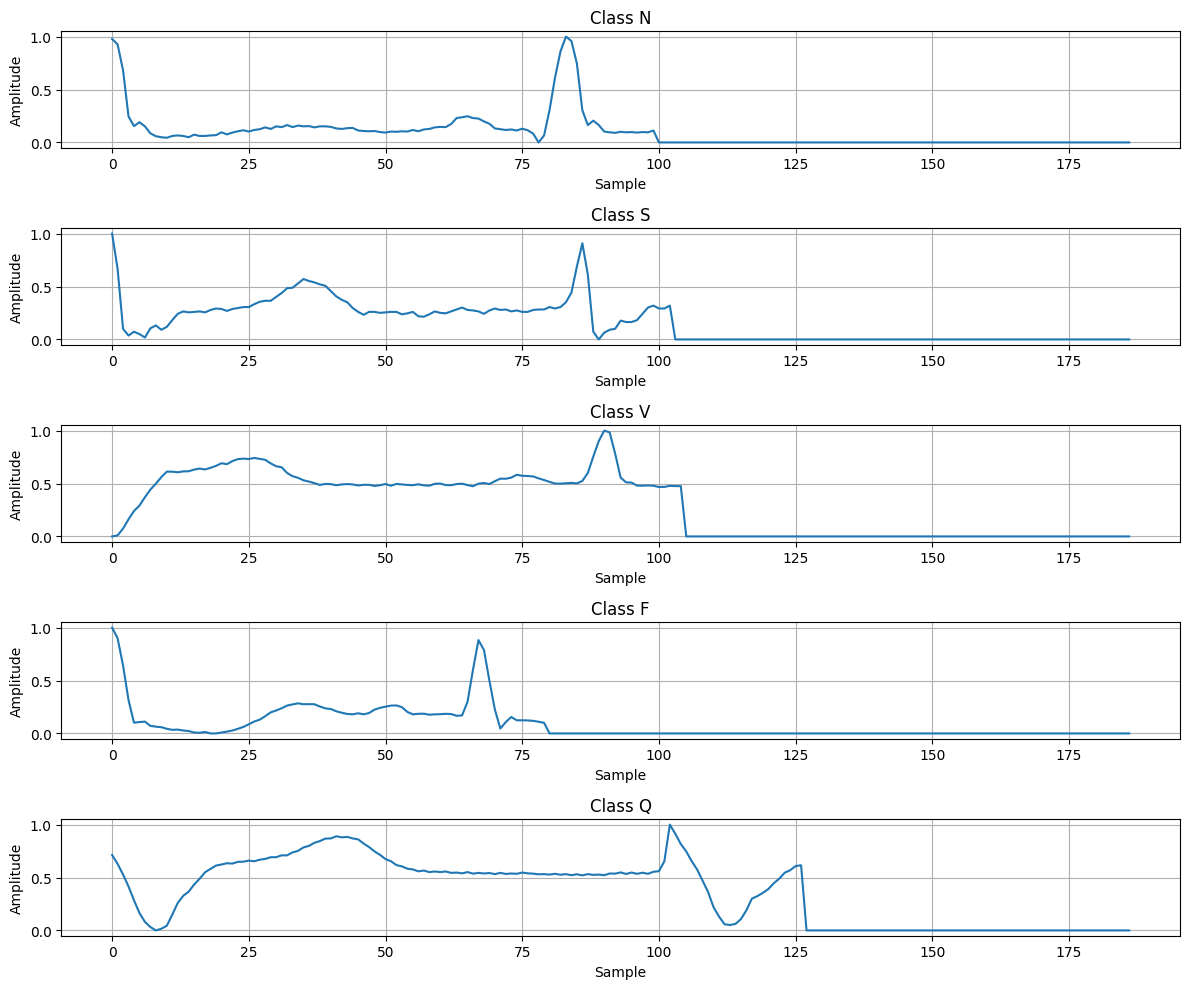

In [8]:
plt.figure(figsize=(12, 10))

for i in range(5):
    index = np.where(y_train_all == i)[0][0]

    plt.subplot(5, 1, i + 1)
    plt.plot(X_train_all[index])
    plt.title(f"Class {class_names[i]}")
    plt.xlabel("Sample")
    plt.ylabel("Amplitude")
    plt.grid(True)

plt.tight_layout()
plt.show()

In [9]:
#Split training data into training and validation
rng = np.random.default_rng(42)

idx = rng.permutation(len(train_df))

n_val = int(0.1 * len(train_df))

val_idx, train_idx = idx[:n_val], idx[n_val:]

X_train = X_train_all[train_idx]
y_train = y_train_all[train_idx]

X_val = X_train_all[val_idx]
y_val = y_train_all[val_idx]

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Testing rows:", len(X_test))

Training rows: 78799
Validation rows: 8755
Testing rows: 21892


In [10]:
#Convert data into PyTorch tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)

X_val = torch.tensor(X_val, dtype=torch.float32)
y_val = torch.tensor(y_val, dtype=torch.long)

X_test = torch.tensor(X_test, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.long)

print(X_train.shape)
print(y_train.shape)

torch.Size([78799, 187])
torch.Size([78799])


In [28]:
import sys
import os
import torch

# Add src folder to Python path
sys.path.insert(0, os.path.abspath("src"))

# # Import model and training data
# from model import ECGNet, cross_entropy
# from prepare import X_train, y_train


# Set random seed
torch.manual_seed(0)

# Create network
model = ECGNet()

# Select first 64 training samples
x = X_train[:64]
y = y_train[:64]

# Forward pass
logits, a2 = model(x, return_activations=True)

# Calculate loss
loss = cross_entropy(logits, y)

# Backpropagation
loss.backward()

# Calculate probabilities
probs = torch.softmax(logits, dim=1)

# One-hot labels
Y = torch.zeros_like(logits)
Y[torch.arange(len(y)), y] = 1.0

# Manual gradient calculation
delta = (probs - Y) / len(y)

manual_W3 = delta.T @ a2

manual_b3 = delta.sum(dim=0)

# Compare gradients
diff_W3 = torch.max(
    torch.abs(manual_W3 - model.W3.grad)
)

diff_b3 = torch.max(
    torch.abs(manual_b3 - model.b3.grad)
)

# Display results
print("Loss:", loss.item())

print("W3 gradient difference:", diff_W3.item())

print("b3 gradient difference:", diff_b3.item())

Loss: 1.7413432598114014
W3 gradient difference: 1.4901161193847656e-08
b3 gradient difference: 1.4901161193847656e-08


In [21]:
torch.manual_seed(0)

model = ECGNet()

total = sum(p.numel() for p in model.parameters())

print("Total parameters:", total)

logits = model(X_train[:128])

loss = cross_entropy(logits, y_train[:128])

print("Initial loss:", loss.item())

Total parameters: 32645
Initial loss: 1.715438723564148


In [29]:

X_all = train_df.iloc[:, :187].values.astype(np.float32)
y_all = train_df.iloc[:, 187].values.astype(np.int64)

X_test = test_df.iloc[:, :187].values.astype(np.float32)
y_test = test_df.iloc[:, 187].values.astype(np.int64)

rng = np.random.default_rng(42)

idx = rng.permutation(len(train_df))

n_val = int(0.1 * len(train_df))

val_idx, train_idx = idx[:n_val], idx[n_val:]

X_train = torch.tensor(X_all[train_idx], dtype=torch.float32)
y_train = torch.tensor(y_all[train_idx], dtype=torch.long)

X_val = torch.tensor(X_all[val_idx], dtype=torch.float32)
y_val = torch.tensor(y_all[val_idx], dtype=torch.long)

X_test = torch.tensor(X_test, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.long)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: torch.Size([78799, 187])
Validation: torch.Size([8755, 187])
Testing: torch.Size([21892, 187])



Training with learning rate: 0.01
Alpha 0.01 | Epoch 1/30 | Train Loss 0.4651 | Val Loss 0.4612 | Train Acc 0.8671 | Val Acc 0.8675
Alpha 0.01 | Epoch 2/30 | Train Loss 0.3869 | Val Loss 0.3825 | Train Acc 0.8936 | Val Acc 0.8948
Alpha 0.01 | Epoch 3/30 | Train Loss 0.3468 | Val Loss 0.3420 | Train Acc 0.9074 | Val Acc 0.9083
Alpha 0.01 | Epoch 4/30 | Train Loss 0.3187 | Val Loss 0.3144 | Train Acc 0.9149 | Val Acc 0.9148
Alpha 0.01 | Epoch 5/30 | Train Loss 0.2979 | Val Loss 0.2942 | Train Acc 0.9213 | Val Acc 0.9218
Alpha 0.01 | Epoch 6/30 | Train Loss 0.2804 | Val Loss 0.2766 | Train Acc 0.9242 | Val Acc 0.9255
Alpha 0.01 | Epoch 7/30 | Train Loss 0.2665 | Val Loss 0.2636 | Train Acc 0.9273 | Val Acc 0.9272
Alpha 0.01 | Epoch 8/30 | Train Loss 0.2545 | Val Loss 0.2510 | Train Acc 0.9297 | Val Acc 0.9294
Alpha 0.01 | Epoch 9/30 | Train Loss 0.2440 | Val Loss 0.2414 | Train Acc 0.9331 | Val Acc 0.9323
Alpha 0.01 | Epoch 10/30 | Train Loss 0.2353 | Val Loss 0.2329 | Train Acc 0.9369 |

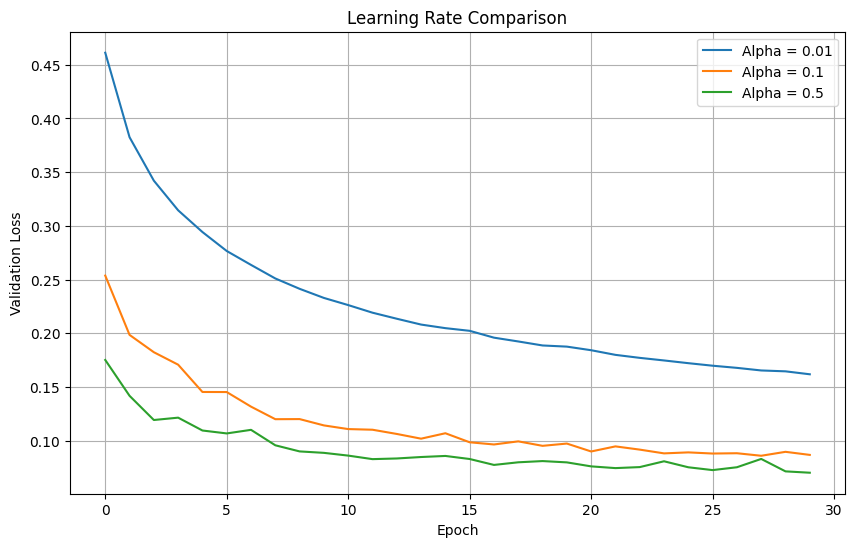

In [32]:
#Training
os.makedirs("results", exist_ok=True)
BATCH_SIZE = 128
EPOCHS = 30
BETA = 0.9
LAMBDA = 1e-4

def evaluate(model, X, y):

    with torch.no_grad():

        logits = model(X)

        loss = cross_entropy(logits, y)

        predictions = torch.argmax(logits, dim=1)

        accuracy = (predictions == y).float().mean()

    return loss.item(), accuracy.item()


def train(alpha):

    torch.manual_seed(0)

    model = ECGNet()

    # Initialize velocities
    velocities = {
        name: torch.zeros_like(parameter)
        for name, parameter in model.named_parameters()
    }

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    best_loss = float("inf")
    best_epoch = 0

    for epoch in range(EPOCHS):

        model.train()

        permutation = torch.randperm(len(X_train))

        for start in range(0, len(X_train), BATCH_SIZE):

            indices = permutation[start:start + BATCH_SIZE]

            xb = X_train[indices]
            yb = y_train[indices]

            logits = model(xb)

            loss = cross_entropy(logits, yb)

            model.zero_grad()

            loss.backward()

            with torch.no_grad():

                for name, parameter in model.named_parameters():

                    gradient = parameter.grad

                    # Weight decay only for weights
                    if name.startswith("W"):
                        gradient = gradient + LAMBDA * parameter

                    # Momentum
                    velocities[name].mul_(BETA).add_(
                        gradient, alpha=1 - BETA
                    )

                    # Parameter update
                    parameter.sub_(
                        alpha * velocities[name]
                    )

        # Evaluate after each epoch
        train_loss, train_acc = evaluate(
            model, X_train, y_train
        )

        val_loss, val_acc = evaluate(
            model, X_val, y_val
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_loss < best_loss:

            best_loss = val_loss
            best_epoch = epoch + 1

            torch.save(
                model.state_dict(),
                f"results/best_model_{alpha}.pth"
            )

        print(
            f"Alpha {alpha} | Epoch {epoch+1}/{EPOCHS} | "
            f"Train Loss {train_loss:.4f} | "
            f"Val Loss {val_loss:.4f} | "
            f"Train Acc {train_acc:.4f} | "
            f"Val Acc {val_acc:.4f}"
        )

    return history, best_epoch


# Compare three learning rates
learning_rates = [0.01, 0.1, 0.5]

all_histories = {}

for alpha in learning_rates:

    print("\nTraining with learning rate:", alpha)

    history, best_epoch = train(alpha)

    all_histories[alpha] = history

    print("Best epoch:", best_epoch)


# Plot validation losses for all learning rates
plt.figure(figsize=(10, 6))

for alpha in learning_rates:

    plt.plot(
        all_histories[alpha]["val_loss"],
        label=f"Alpha = {alpha}"
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Learning Rate Comparison")
plt.legend()
plt.grid()
plt.savefig("results/learning_rate_comparison.png", dpi=300)
plt.show()

In [33]:
best_alpha = min(
    learning_rates,
    key=lambda a: min(all_histories[a]["val_loss"])
)

print("\nBest learning rate:", best_alpha)


Best learning rate: 0.5


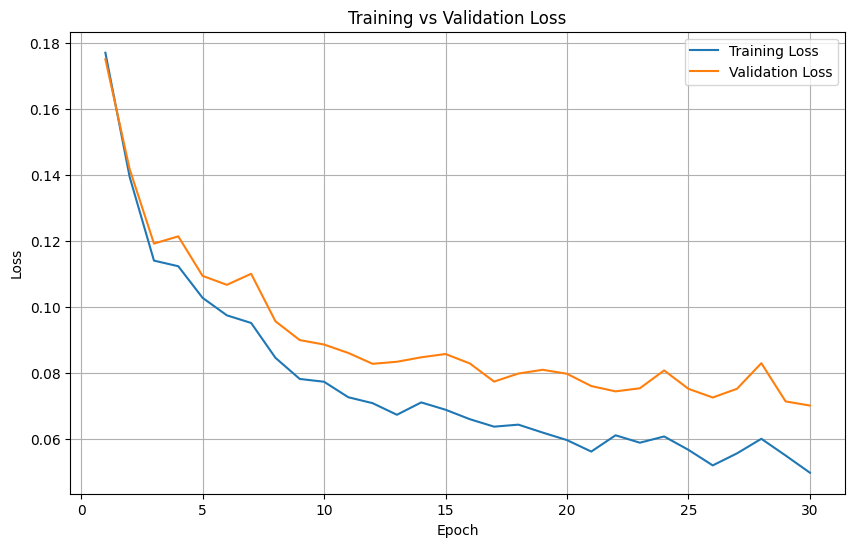

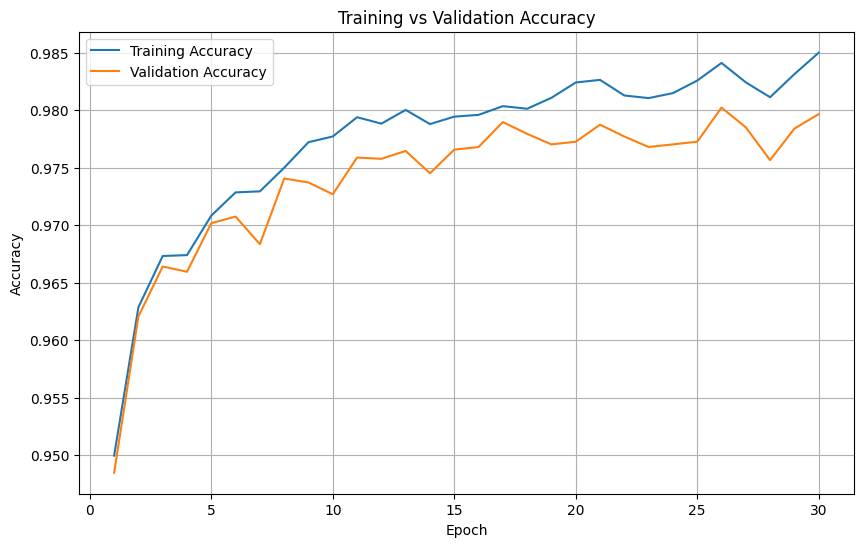

In [34]:
history = all_histories[best_alpha]

epochs = range(1, EPOCHS + 1)

# Loss graph
plt.figure(figsize=(10, 6))

plt.plot(epochs, history["train_loss"], label="Training Loss")
plt.plot(epochs, history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")

plt.legend()
plt.grid()

plt.savefig("results/loss_curves.png", dpi=300)
plt.show()


# Accuracy graph
plt.figure(figsize=(10, 6))

plt.plot(epochs, history["train_acc"], label="Training Accuracy")
plt.plot(epochs, history["val_acc"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")

plt.legend()
plt.grid()

plt.savefig("results/accuracy_curves.png", dpi=300)
plt.show()

In [35]:
best_alpha = 0.01  # Replace with the selected learning rate

model = ECGNet()

model.load_state_dict(
    torch.load(
        f"results/best_model_{best_alpha}.pth",
        map_location="cpu"
    )
)

model.eval()

with torch.no_grad():

    logits = model(X_test)

    predictions = torch.argmax(logits, dim=1)

print("Predictions:", predictions[:20])

Predictions: tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])


In [36]:
correct = (predictions == y_test).sum().item()

accuracy = correct / len(y_test)

print("Test Accuracy:", accuracy)
print("Test Accuracy (%):", accuracy * 100)

Test Accuracy: 0.9550977526036909
Test Accuracy (%): 95.5097752603691


In [38]:

def accuracy_score(y_true, y_pred):

    return (y_true == y_pred).float().mean().item()


def confusion_matrix(y_true, y_pred, num_classes=5):

    matrix = torch.zeros(
        num_classes, num_classes, dtype=torch.long
    )

    for actual, predicted in zip(y_true, y_pred):

        matrix[actual.item(), predicted.item()] += 1

    return matrix


def per_class_accuracy(matrix):

    result = []

    for i in range(len(matrix)):

        correct = matrix[i, i].item()

        total = matrix[i].sum().item()

        result.append(correct / total if total > 0 else 0)

    return result

In [39]:

matrix = confusion_matrix(y_test, predictions)

class_acc = per_class_accuracy(matrix)

balanced_acc = sum(class_acc) / 5

print("\nConfusion Matrix:")
print(matrix)

print("\nPer Class Accuracy:")

names = ["N", "S", "V", "F", "Q"]

for name, value in zip(names, class_acc):

    print(name, round(value * 100, 2), "%")

print("\nOverall Accuracy:", accuracy * 100, "%")

print("Balanced Accuracy:", balanced_acc * 100, "%")


Confusion Matrix:
tensor([[17989,    39,    79,     2,     9],
        [  272,   262,    22,     0,     0],
        [  230,     4,  1198,     6,    10],
        [   89,     0,    44,    29,     0],
        [  161,     0,    16,     0,  1431]])

Per Class Accuracy:
N 99.29 %
S 47.12 %
V 82.73 %
F 17.9 %
Q 88.99 %

Overall Accuracy: 95.5097752603691 %
Balanced Accuracy: 67.20777631050827 %


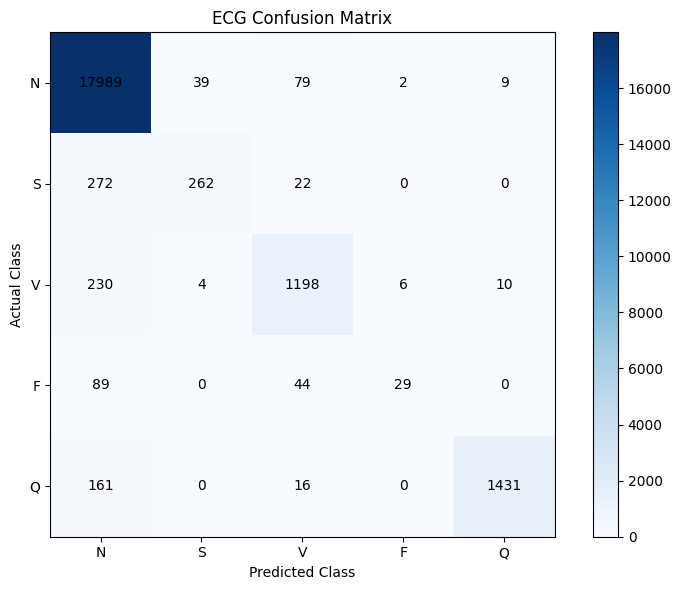

In [40]:

plt.figure(figsize=(8, 6))

plt.imshow(matrix.numpy(), cmap="Blues")

plt.xticks(range(5), names)
plt.yticks(range(5), names)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.title("ECG Confusion Matrix")

plt.colorbar()

for i in range(5):
    for j in range(5):

        plt.text(
            j, i,
            str(matrix[i, j].item()),
            ha="center",
            va="center"
        )

plt.tight_layout()

plt.savefig("results/confusion_matrix.png", dpi=300)

plt.show()